In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from skimage import data, img_as_float
from skimage import exposure


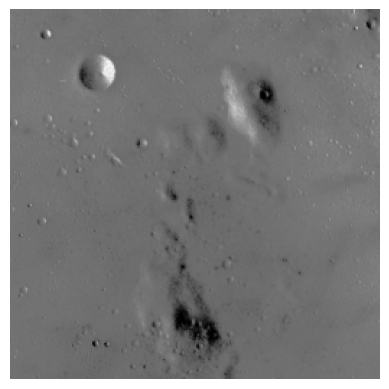

In [2]:
img = data.moon()
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()


### Lab 4 Tutorial: Contrast Stretching (2nd and 98th Percentiles)


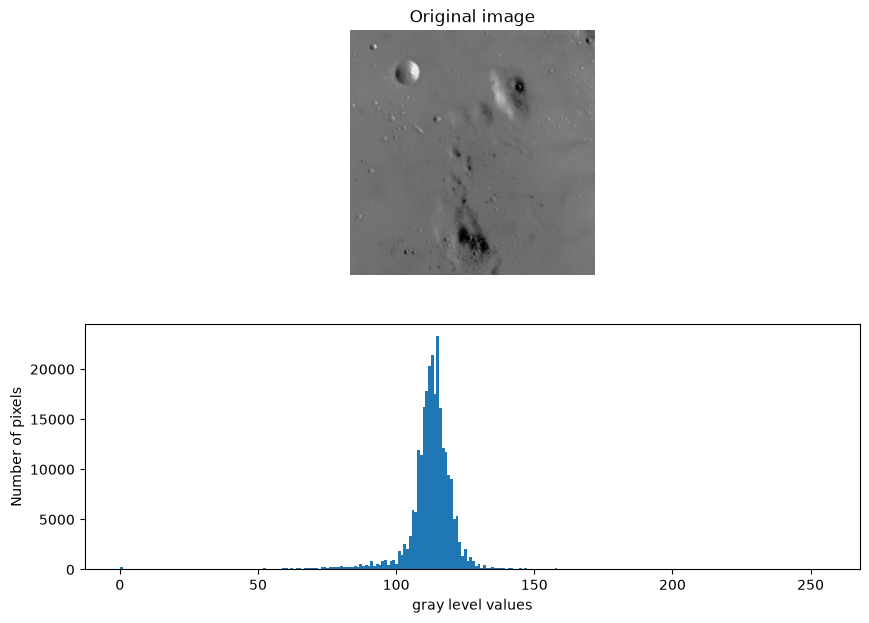

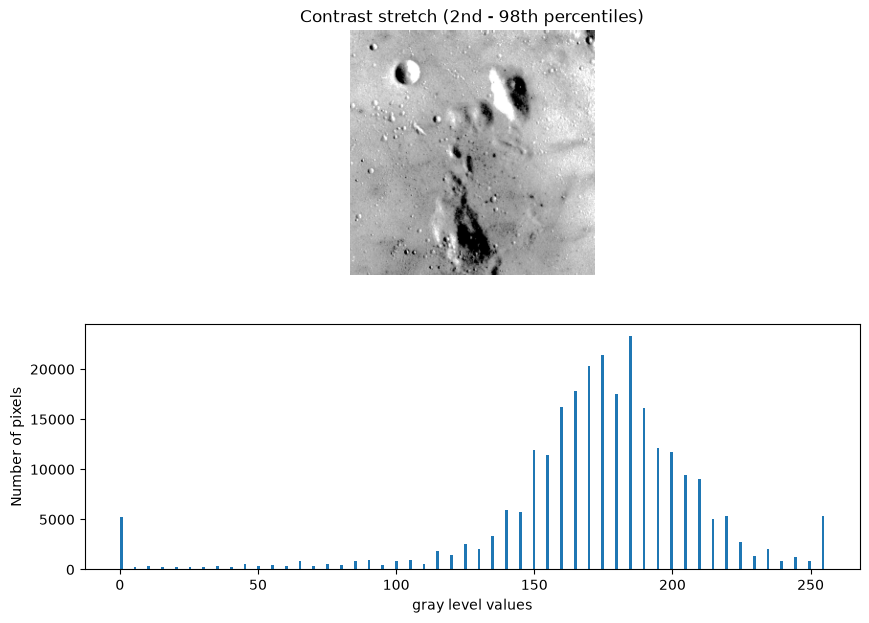

In [3]:
# Contrast stretching (2nd and 98th percentiles from lab manual)
p2, p98 = np.percentile(img, (2, 98))
img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))

fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title('Original image')
fig.add_subplot(2, 1, 2)
plt.hist(img.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale, cmap='gray')
plt.axis('off')
plt.title('Contrast stretch (2nd - 98th percentiles)')
fig.add_subplot(2, 1, 2)
plt.hist(img_rescale.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()


### Task#1: Rescale intensity values within 3rd and 80th percentiles and plot histogram


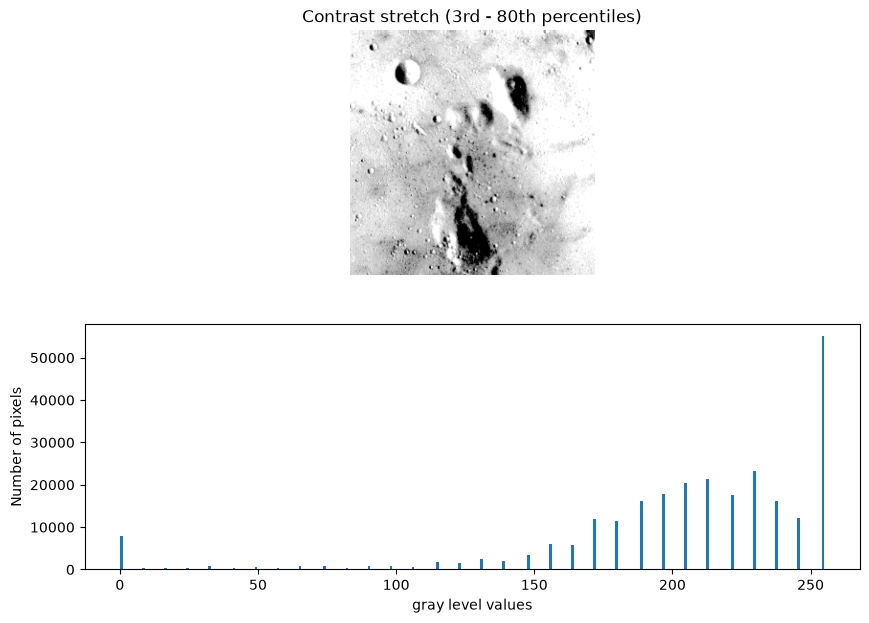

In [4]:
# Task#1: Rescale intensity values between 3rd and 80th percentiles
p3, p80 = np.percentile(img, (3, 80))

img_rescale_3_80 = exposure.rescale_intensity(
    img,
    in_range=(p3, p80)
)

fig = plt.figure(figsize=(10, 7))

fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale_3_80, cmap='gray')
plt.axis('off')
plt.title('Contrast stretch (3rd - 80th percentiles)')

fig.add_subplot(2, 1, 2)
plt.hist(img_rescale_3_80.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')

plt.show()


### Task#2: Histogram Equalization using exposure.equalize_hist (Flattened Histogram)


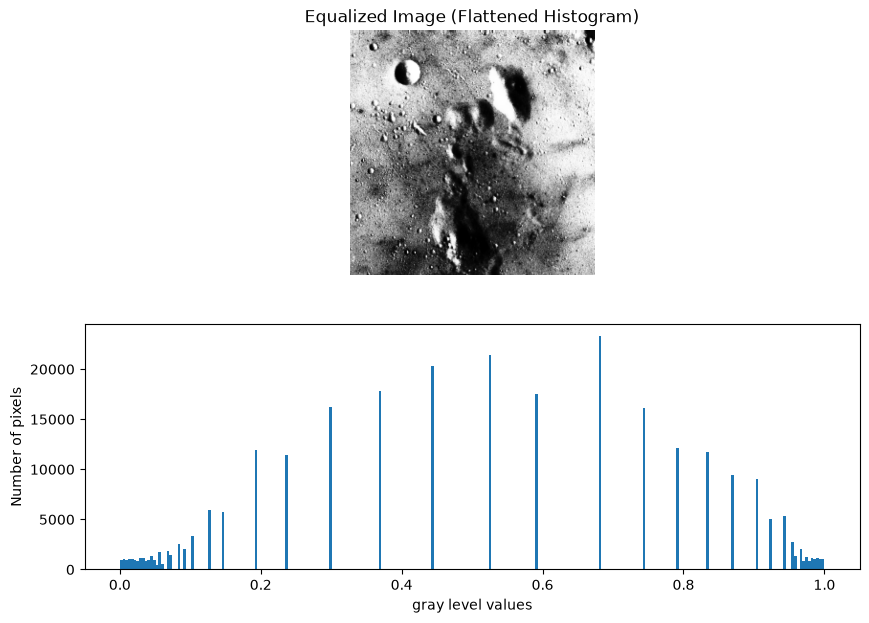

In [5]:
# Task#2: Using exposure.equalize_hist to flatten the histogram
img_eq = exposure.equalize_hist(img)

fig = plt.figure(figsize=(10, 7))

fig.add_subplot(2, 1, 1)
plt.imshow(img_eq, cmap='gray')
plt.axis('off')
plt.title('Equalized Image (Flattened Histogram)')

fig.add_subplot(2, 1, 2)
# equalize_hist returns float values in [0, 1]
plt.hist(img_eq.flat, bins=256, range=(0, 1))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')

plt.show()


### Task#3: Histogram Matching (Chelsea matched with Rocket as reference)


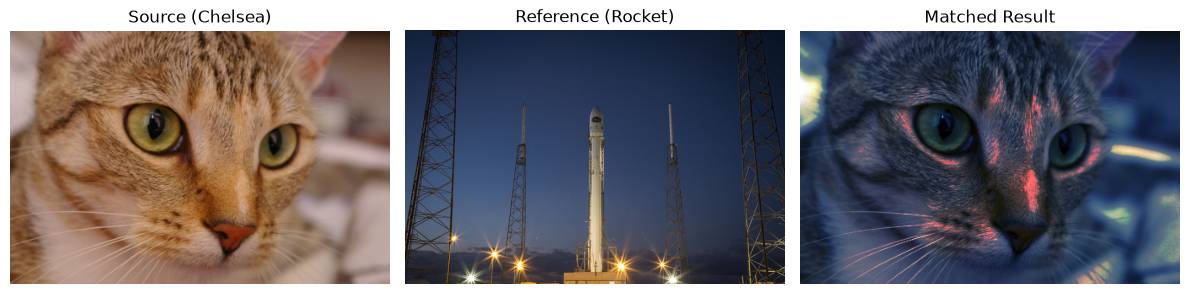

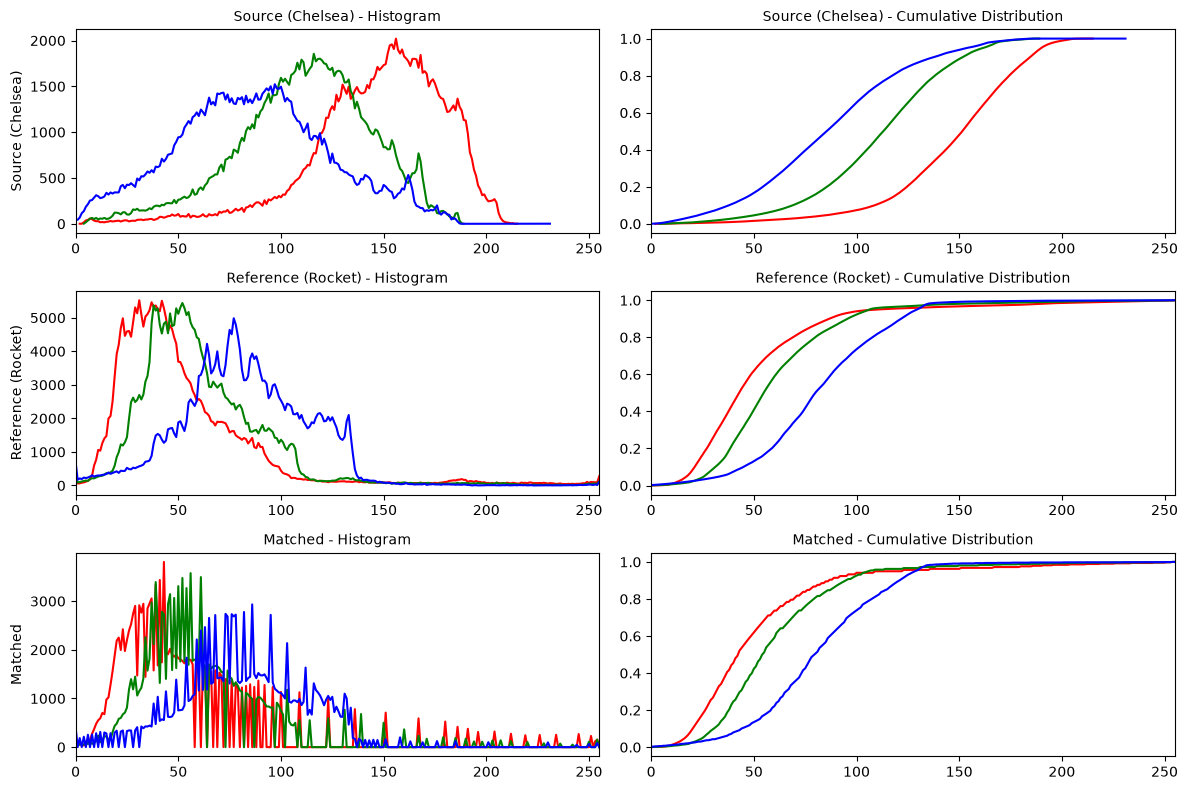

In [6]:
# Task#3: Histogram Matching using Chelsea and Rocket (as reference)
image = data.chelsea()
reference = data.rocket()

# Match histograms across color channels
matched = exposure.match_histograms(image, reference, channel_axis=-1)

# 1. Display images side-by-side
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))
for ax, img_item, title in zip(
    (ax1, ax2, ax3),
    (image, reference, matched),
    ('Source (Chelsea)', 'Reference (Rocket)', 'Matched Result')
):
    ax.imshow(img_item)
    ax.set_title(title, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.show()

# 2. Display Histograms and Cumulative Distributions
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 8))

for i, img_item, label in zip(
    range(3),
    [image, reference, matched],
    ['Source (Chelsea)', 'Reference (Rocket)', 'Matched']
):
    for c, c_color in enumerate(('red', 'green', 'blue')):
        img_slice = img_item[:, :, c]
        
        # Regular Histogram
        counts, centers = exposure.histogram(img_slice)
        axes[i, 0].plot(centers, counts, color=c_color, label=c_color.capitalize())
        axes[i, 0].set_ylabel(label, fontsize=10)
        axes[i, 0].set_title(f'{label} - Histogram', fontsize=10)
        axes[i, 0].set_xlim(0, 255)
        
        # Cumulative Distribution
        counts_cum, centers_cum = exposure.cumulative_distribution(img_slice)
        axes[i, 1].plot(centers_cum, counts_cum, color=c_color, label=c_color.capitalize())
        axes[i, 1].set_title(f'{label} - Cumulative Distribution', fontsize=10)
        axes[i, 1].set_xlim(0, 255)

plt.tight_layout()
plt.show()
